1. Calidad del cierre diario. ¿Es un acumulado real? Si tiene cientos o miles de bajadas y negativos y su nombre sugiere que es una resta (“Resto”), es una columna calculada: se descarta. Si tiene pocos extremos (>=1e6), es corregible en la Fase 2.1 y se queda.

2. Disponibilidad. Porcentaje de nulos. Si falta un año entero (el 30 % de antes), queda condicionada a que en la Fase 2 se impute o se recorte.

3. Relación con el target. Spearman con el frío de mañana ≥ 0,4. Uso Spearman porque es robusto a los extremos que todavía no limpiaste. El umbral 0,4 es razonable: deja afuera lo que se relaciona débilmente y no es tan estricto, porque la selección final se hace en la Fase 2.3.

4. No contener al target. Si la columna incluye el consumo de frío (Spearman con el frío de hoy ≈ 0,9 o más, y sentido físico de que lo contiene), no es una variable nueva: es el frío con otro nombre. Se marca como “proxy del target”.

In [1]:
import sys
from pathlib import Path

import pandas as pd

# Raíz del proyecto (para poder importar src/ desde notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.auxiliar_functions import RAW_DATA_DIR, ARCHIVOS_CRUDOS

print("Raíz del proyecto:", PROJECT_ROOT)
print("Archivos:", ARCHIVOS_CRUDOS)

Raíz del proyecto: c:\Users\genat\proyectos\tp-final-datos-ii
Archivos: ['Totalizadores Planta 2020_2022.xlsx', 'Totalizadores Planta - 2021_2023.xlsx', 'Totalizadores Planta 2022_2023.xlsx']


In [2]:
import pandas as pd
from src.auxiliar_functions import RAW_DATA_DIR, ARCHIVOS_CRUDOS

for hoja in ["Consolidado Produccion", "Totalizadores Produccion"]:
    print(f"\n===== {hoja} =====")
    columnas = {}
    for archivo in ARCHIVOS_CRUDOS:
        df = pd.read_excel(RAW_DATA_DIR / archivo, sheet_name=hoja)
        columnas[archivo] = set(df.columns)
        print(f"{archivo}: {df.shape[0]} filas, {df.shape[1]} columnas")

    comunes = set.intersection(*columnas.values())
    print("Columnas en los 3 archivos:", len(comunes))
    for archivo, cols in columnas.items():
        solo_aca = cols - comunes
        if solo_aca:
            print(f"  Solo en {archivo}: {sorted(solo_aca)}")


===== Consolidado Produccion =====
Totalizadores Planta 2020_2022.xlsx: 15573 filas, 12 columnas
Totalizadores Planta - 2021_2023.xlsx: 15317 filas, 13 columnas
Totalizadores Planta 2022_2023.xlsx: 12010 filas, 18 columnas
Columnas en los 3 archivos: 12
  Solo en Totalizadores Planta - 2021_2023.xlsx: ['Hl de Mosto Copia']
  Solo en Totalizadores Planta 2022_2023.xlsx: ['Hl de Mosto Copia', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18']

===== Totalizadores Produccion =====
Totalizadores Planta 2020_2022.xlsx: 15573 filas, 40 columnas
Totalizadores Planta - 2021_2023.xlsx: 15316 filas, 40 columnas
Totalizadores Planta 2022_2023.xlsx: 12009 filas, 41 columnas
Columnas en los 3 archivos: 39
  Solo en Totalizadores Planta 2020_2022.xlsx: ['Hl Reserva 7']
  Solo en Totalizadores Planta - 2021_2023.xlsx: ['Hl Reserva 7']
  Solo en Totalizadores Planta 2022_2023.xlsx: ['Hl Session IPA', 'Id']


Consolidado Produccion: hay 12 columnas comunes a los 3 archivos (DIA, HORA y 10 de producción). Lo extra es basura: Hl de Mosto Copia es una copia y las Unnamed son columnas vacías del Excel. Trabajamos con las 12 comunes.

Totalizadores Produccion: Hl Reserva 7 desaparece y aparece Hl Session IPA. Las dos están en el mismo lugar de la lista. Lo más probable es que sea la misma columna renombrada: un casillero “reserva” que después se usó para una cerveza nueva esto es una hipotesis, lo confirmamos viendo si en el solapamiento entre archivos tienen los mismos valores. Id es un número de fila, basura.

In [3]:
# Cierre diario (23:59) de una hoja, unificando los 3 archivos con la misma regla que en EE:
# - dentro de cada archivo, el primer cierre de cada día (por las jornadas apiladas)
# - entre archivos, gana el más reciente
def cierre_diario(hoja):
    partes = []
    for prioridad, archivo in enumerate(ARCHIVOS_CRUDOS):  # 0 = más viejo, 2 = más reciente
        df = pd.read_excel(RAW_DATA_DIR / archivo, sheet_name=hoja)
        df = df[df["HORA"].astype(str).str.startswith("23:59")]
        df = df.drop_duplicates(subset="DIA", keep="first").copy()
        df["prioridad"] = prioridad
        # Convertir a número todas las columnas de medición (un ' ' suelto vuelve texto la columna entera)
        columnas_medicion = [c for c in df.columns if c not in ["DIA", "HORA"]]
        df[columnas_medicion] = df[columnas_medicion].apply(pd.to_numeric, errors="coerce")
        partes.append(df)
    todo = pd.concat(partes).sort_values(["DIA", "prioridad"])
    return todo.drop_duplicates(subset="DIA", keep="last").drop(columns="prioridad").reset_index(drop=True)

df_prod_diario = cierre_diario("Consolidado Produccion")
df_tot_prod_diario = cierre_diario("Totalizadores Produccion")
print("Consolidado Produccion:", df_prod_diario.shape, "| Totalizadores Produccion:", df_tot_prod_diario.shape)

# Columnas numéricas: cuántos días con cierre en 0 y estadísticas básicas
for nombre, df in [("Consolidado Produccion", df_prod_diario), ("Totalizadores Produccion", df_tot_prod_diario)]:
    numericas = df.select_dtypes("number")
    resumen = pd.DataFrame({
        "dias_en_cero_%": (numericas == 0).mean().mul(100).round(1),
        "media": numericas.mean().round(1),
        "max": numericas.max(),
        "nulos": numericas.isna().sum(),
    })
    print(f"\n===== {nombre} =====")
    print(resumen.sort_values("dias_en_cero_%").to_string())

Consolidado Produccion: (1185, 18) | Totalizadores Produccion: (1185, 42)

===== Consolidado Produccion =====
                     dias_en_cero_%   media      max  nulos
Unnamed: 14                     0.0     NaN      NaN   1185
Unnamed: 15                     0.8  2782.9   9193.0   1143
Unnamed: 16                     0.8  1468.1   4537.0   1143
Unnamed: 17                     0.9  1182.6   3287.0   1143
Hl Producido Bodega             2.3  8546.8  15315.5      0
Unnamed: 18                     2.5   285.5   3139.0   1143
Hl Cerveza Filtrada             4.6  7947.3  15883.0      0
Hl Cerveza Envasada             5.8  8483.1  15989.0      0
Cocimientos Diarios             8.4    10.3     24.0    252
Hl de Mosto Copia               9.8  5098.6  10303.0    358
Hl Cerveza Cocina              11.6  8610.6  16318.8      0
Hl de Mosto                    11.6  5474.4  10303.0      0
Hl Cerveza L4                  15.4  4058.5   6544.0      0
Hl Cerveza L2                  17.6  1366.5   4136

las Unnamed: 14 a 18, Hl de Mosto Copia e Id son columnas basura, las descartamos

Unnamed: 15 a 18 tienen números en 42 días, son columnas sin nombre en el Excel de 2022_2023 que seguramente alguien utilizo para cálculos sueltos al costado de la tabla


Hl Reserva 7 y Hl Session IPA no importan: valen 0 siempre y la hipótesis de que es la misma columna renombrada da igual, descartamos las dos.

con las marcas de cervezas, 9 están en 0 el 100 % de los días y otras 10 tienen más del 98 % de días en 0. Se descartan. Solo Tecate (39 % de días en 0) y algo Heineken (73 %) tienen producción regular. Además, el total de mosto ya está en Hl de Mosto de la otra hoja, así que el detalle por marca aporta poco

Hl Cerveza L2 a L5 y Cocimientos Diarios están en las dos hojas, con estadísticas idénticas. Se usan una sola vez, desde Consolidado Produccion.

Nivel Silo Bagazo Sur (2) y Nivel Tk Restos Lev no son acumulados (máximo de ~95 a 100, son porcentajes de llenado) y tienen muchos nulos. Nivel Silo Bagazo Norte (1) no aparece en la tabla. Como select_dtypes("number") solo toma columnas numéricas, debe estar como texto en algún archivo.



In [4]:
# Frio diario desde Consolidado EE con la misma función (exploratorio: sin limpiar inválidos)
df_ee_diario = cierre_diario("Consolidado EE")[["DIA", "Frio (Kw)"]]
df_ee_diario["Frio (Kw)"] = pd.to_numeric(df_ee_diario["Frio (Kw)"], errors="coerce")
df_ee_diario = df_ee_diario[df_ee_diario["Frio (Kw)"].between(0, 100_000)]

candidatas = ["Hl de Mosto", "Hl Cerveza Cocina", "Hl Producido Bodega", "Hl Cerveza Filtrada",
              "Hl Cerveza Envasada", "Hl Cerveza L2", "Hl Cerveza L3", "Hl Cerveza L4", "Hl Cerveza L5",
              "Cocimientos Diarios"]

# Unimos por fecha y reindexamos al calendario para que shift(-1) sea el día siguiente
df_cruce = df_prod_diario[["DIA"] + candidatas].merge(df_ee_diario, on="DIA").set_index("DIA").asfreq("D")
df_cruce["Frio_manana"] = df_cruce["Frio (Kw)"].shift(-1)

correlaciones = pd.DataFrame({
    "r_con_frio_hoy": df_cruce[candidatas].corrwith(df_cruce["Frio (Kw)"]),
    "r_con_frio_manana": df_cruce[candidatas].corrwith(df_cruce["Frio_manana"]),
}).round(3).sort_values("r_con_frio_manana", ascending=False)
print(correlaciones)

                     r_con_frio_hoy  r_con_frio_manana
Hl Producido Bodega           0.620              0.551
Hl Cerveza Envasada           0.503              0.478
Hl Cerveza Filtrada           0.584              0.448
Hl Cerveza L4                 0.446              0.427
Hl de Mosto                   0.482              0.394
Hl Cerveza Cocina             0.474              0.393
Cocimientos Diarios           0.462              0.385
Hl Cerveza L3                 0.357              0.347
Hl Cerveza L2                 0.303              0.271
Hl Cerveza L5                 0.240              0.206


La mejor es Hl Producido Bodega: r = 0,55, seguida de Envasada (0,48), Filtrada (0,45) y L4 (0,43). Debemos tener en cuenta la estacionalidad, ya que ne verano se produce y se vende mas cerveza, y tambien hace mas calos. Parte de esta correlacion puede venir de que las dos variables dependen de la estacion, no de que producir enfrie mas. 

In [5]:
# Hoja horaria unificada: misma regla que en EE (primeras 25 filas por día y gana el archivo más reciente)
def horario_unificado(hoja, columnas, renombrar=None):
    partes = []
    for prioridad, archivo in enumerate(ARCHIVOS_CRUDOS):
        df = pd.read_excel(RAW_DATA_DIR / archivo, sheet_name=hoja)
        df = df.rename(columns=renombrar or {})  # unifica nombres que cambian entre archivos
        df = df.reindex(columns=["DIA", "HORA"] + columnas)  # si una columna no existe en este archivo, queda NaN
        df[columnas] = df[columnas].apply(pd.to_numeric, errors="coerce")
        df = df.dropna(subset=["DIA"]).groupby("DIA").head(25)  # jornadas apiladas
        df["prioridad"] = prioridad
        partes.append(df)
    todo = pd.concat(partes)
    # Por cada día, nos quedamos con las filas del archivo de mayor prioridad
    prioridad_max = todo.groupby("DIA")["prioridad"].transform("max")
    return todo[todo["prioridad"] == prioridad_max].drop(columns="prioridad").reset_index(drop=True)

columnas_prod = ["Hl de Mosto", "Hl Cerveza Cocina", "Hl Producido Bodega", "Hl Cerveza Filtrada",
                 "Hl Cerveza Envasada", "Hl Cerveza L2", "Hl Cerveza L3", "Hl Cerveza L4", "Hl Cerveza L5",
                 "Cocimientos Diarios"]
df_prod_horario = horario_unificado("Consolidado Produccion", columnas_prod)
print(df_prod_horario.shape, "| días:", df_prod_horario["DIA"].nunique())

(29698, 12) | días: 1190


In [6]:
hora_txt = df_prod_horario["HORA"].astype(str)

# a) Horas "mal escritas": que no terminan en :00:00 (salvo el cierre 23:59)
horas_raras = hora_txt[~hora_txt.str.endswith(":00:00") & ~hora_txt.str.startswith("23:59")]
print("a) Horas con segundos o formato raro:", len(horas_raras), "| ejemplos:", horas_raras.unique()[:8])

# b) Días incompletos (menos de 24 lecturas)
lecturas = df_prod_horario.groupby("DIA").size()
print("b) Días con < 24 lecturas:", (lecturas < 24).sum())

# b2) Días donde se repite una hora (comparando HH:MM, sin los segundos)
df_prod_horario["HH_MM"] = hora_txt.str[:5]
repetidas = df_prod_horario[df_prod_horario.duplicated(subset=["DIA", "HH_MM"], keep=False)]
dias_con_repetidas = repetidas["DIA"].nunique()
print(f"b2) Días con alguna hora repetida: {dias_con_repetidas} ({len(repetidas)} filas involucradas)")
if dias_con_repetidas > 0:
    print(repetidas[["DIA", "HORA"] + columnas_prod[:3]].head(10).to_string(index=False))

# c) a e) Por columna: sin reinicio a las 00:00, acumulado que baja, valores imposibles, saltos anómalos
df_ord = df_prod_horario.sort_values(["DIA", "HORA"])
filas = []
for col in columnas_prod:
    incremento = df_ord.groupby("DIA")[col].diff()
    medianoche = df_ord[hora_txt.loc[df_ord.index].str.startswith("00:00")][col]
    p999 = incremento[incremento > 0].quantile(0.999)
    filas.append({
        "columna": col,
        "dias_sin_reinicio": (medianoche > 0).sum(),
        "horas_que_bajan": (incremento < 0).sum(),
        "valores_negativos": (df_ord[col] < 0).sum(),
        "valores_>=1e6": (df_ord[col] >= 1_000_000).sum(),
        "p99.9_incremento": round(p999, 1),
        "nulos": df_ord[col].isna().sum(),
    })
print("\nc) Controles por columna:")
print(pd.DataFrame(filas).set_index("columna").to_string())

a) Horas con segundos o formato raro: 420 | ejemplos: <StringArray>
['20:00:01', '22:00:01', '12:00:01', '15:00:01', '03:00:01', '02:00:01',
 '10:00:01', '13:00:01']
Length: 8, dtype: str
b) Días con < 24 lecturas: 8
b2) Días con alguna hora repetida: 3 (6 filas involucradas)
       DIA     HORA  Hl de Mosto  Hl Cerveza Cocina  Hl Producido Bodega
2020-09-05 15:00:00       5076.0             7646.7              7395.35
2020-09-05 15:00:00       5452.0             8323.5              8014.25
2022-12-10 16:00:00          0.0                0.0               529.50
2022-12-10 16:00:00          0.0                0.0               529.50
2023-02-28 00:00:00          0.0                0.0                 0.00
2023-02-28 00:00:00          0.0                0.0                 0.00

c) Controles por columna:
                     dias_sin_reinicio  horas_que_bajan  valores_negativos  valores_>=1e6  p99.9_incremento  nulos
columna                                                               

Las 420 horas con :01 no son un problema, porque siempre se filtra con startswith o comparando HH:MM

los dias incompletos son los mismos 8 que en Consolidado EE, con las mismas fechas exactas. Tiene sentido, porque todas las hojas salen del mismo registrador.

hay 3 horas repetidas, que no rompen nada pero las modificaremos, 2020-09-05 15:00 aparece dos veces y falta 16:00, y el segundo valor es mayor que el primero, por lo que es la lectura de las 16:00.
2022-12-10 el orden de las horas es 13, 16, 15, 16: la de las 14:00 está etiquetada como 16:00.
2023-02-28 ya esta contemplada en la 1.1

Las columnas de producción están limpias. Sin valores imposibles, sin negativos, siempre reinician a las 00:00 y nunca bajan.

Cocimiento Diarios tiene 70% de sus valores nulos en el archivo 2020_2022, ya que en este periodo no se registraba, y en 52 dias no reinicia o no baja. Tambien tiene 252 dias sin datos y si informacion esta ya en Hl de Mosto, ya que los cocimientos son los lotes de mosto, por  lo que la descartamos.
 



In [7]:
# Horas que debería tener un día completo, en orden
HORAS_ESPERADAS = [f"{h:02d}:00" for h in range(24)] + ["23:59"]

def normalizar_horas(df):
    """Corrige las etiquetas de HORA sin tocar los valores medidos.
    Supone que las filas de cada día están en el orden del Excel (no reordenar por HORA antes)."""
    df = df.copy()
    df["HORA_ORIGINAL"] = df["HORA"].astype(str)

    # 1) Quitar los segundos: '04:00:01' -> '04:00'
    df["HORA"] = df["HORA_ORIGINAL"].str[:5]

    # 2) Un '00:00' que no es la primera fila del día es el inicio de otra jornada: se descarta
    posicion = df.groupby("DIA").cumcount()
    cero_intruso = (df["HORA"] == "00:00") & (posicion > 0)
    df = df[~cero_intruso].copy()

    # 3) En los días con las 25 filas, la posición indica la hora: corregimos las etiquetas que no coinciden
    posicion = df.groupby("DIA").cumcount()
    filas_del_dia = df.groupby("DIA")["HORA"].transform("size")
    hora_esperada = posicion.map(lambda i: HORAS_ESPERADAS[i] if i < 25 else None)
    mal_etiquetada = (filas_del_dia == 25) & (df["HORA"] != hora_esperada)
    df.loc[mal_etiquetada, "HORA"] = hora_esperada[mal_etiquetada]

    print(f"Filas '00:00' intrusas eliminadas: {cero_intruso.sum()}")
    print(f"Horas mal etiquetadas corregidas: {mal_etiquetada.sum()}")
    return df

df_prod_horario_ok = normalizar_horas(df_prod_horario)

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 2


In [8]:
# 1) Ya no debería haber horas repetidas
repetidas = df_prod_horario_ok.duplicated(subset=["DIA", "HORA"]).sum()
print("Horas repetidas después del arreglo:", repetidas)

# 2) Las filas corregidas: etiqueta original vs nueva
cambiadas = df_prod_horario_ok[df_prod_horario_ok["HORA_ORIGINAL"].str[:5] != df_prod_horario_ok["HORA"]]
print(cambiadas[["DIA", "HORA_ORIGINAL", "HORA", "Hl de Mosto", "Hl Producido Bodega"]].to_string(index=False))

# 3) En los días corregidos el acumulado tiene que seguir subiendo (nunca bajar)
dias_corregidos = cambiadas["DIA"].unique()
tramo = df_prod_horario_ok[df_prod_horario_ok["DIA"].isin(dias_corregidos)].sort_values(["DIA", "HORA"])
bajadas = (tramo.groupby("DIA")["Hl Producido Bodega"].diff() < 0).sum()
print("\nHoras que bajan en los días corregidos (debería ser 0):", bajadas)

Horas repetidas después del arreglo: 0
       DIA HORA_ORIGINAL  HORA  Hl de Mosto  Hl Producido Bodega
2020-09-05      15:00:00 16:00       5452.0              8014.25
2022-12-10      16:00:00 14:00          0.0               529.50

Horas que bajan en los días corregidos (debería ser 0): 0


In [9]:
diferencia = df_prod_diario["Hl Cerveza Envasada"] - df_prod_diario[["Hl Cerveza L2", "Hl Cerveza L3", "Hl Cerveza L4", "Hl Cerveza L5"]].sum(axis=1)
print(diferencia.describe())

count    1185.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
dtype: float64


vemos algo bueno para lo que sigue, una de las candidatas Hl cerveza envasada, es la suma de las 4 lineas de envasado. Si metemos las 5 en un modelo es informacion repetida. Lo mismo pasa, en menor medida, con Bodega, Filtrada y Envasada, que son etapas consecutivas del mismo proceso: la cerveza que se produce en bodega después se filtra y se envasa. Deberían estar muy correlacionadas entre sí.

esto lo tendremos en cuenta mas adelante

Lista de candidatas: "Hl de Mosto", "Hl Cerveza Cocina", "Hl Producido Bodega", "Hl Cerveza Filtrada",
                 "Hl Cerveza Envasada", "Hl Cerveza L2", "Hl Cerveza L3", "Hl Cerveza L4", "Hl Cerveza L5"
                 

In [27]:
def controles_calidad(df_horario, columnas):
    """Controles por columna sobre una hoja horaria (ya normalizada con normalizar_horas)."""
    df_ord = df_horario.sort_values(["DIA", "HORA"])
    filas = []
    for col in columnas:
        incremento = df_ord.groupby("DIA")[col].diff()
        medianoche = df_ord.loc[df_ord["HORA"] == "00:00", col]
        filas.append({
            "columna": col,
            "nulos_%": round(df_ord[col].isna().mean() * 100, 1),
            "dias_sin_reinicio": (medianoche > 0).sum(),
            "horas_que_bajan": (incremento < 0).sum(),
            "negativos": (df_ord[col] < 0).sum(),
            ">=1e6": (df_ord[col] >= 1_000_000).sum(),
            "p99.9_incremento": round(incremento[incremento > 0].quantile(0.999), 1),
        })
    return pd.DataFrame(filas).set_index("columna")


def correlacion_con_frio(df_diario_hoja, columnas):
    """Correlación del cierre diario de cada columna con Frio de hoy y de mañana."""
    cruce = df_diario_hoja[["DIA"] + columnas].merge(df_ee_diario, on="DIA").set_index("DIA").asfreq("D")
    cruce["Frio_manana"] = cruce["Frio (Kw)"].shift(-1)
    return pd.DataFrame({
        "r_con_frio_hoy": cruce[columnas].corrwith(cruce["Frio (Kw)"]),
        "r_con_frio_manana": cruce[columnas].corrwith(cruce["Frio_manana"]),
        "spearman_hoy": cruce[columnas].corrwith(cruce["Frio (Kw)"], method="spearman"),
        "spearman_manana": cruce[columnas].corrwith(cruce["Frio_manana"], method="spearman"),
        "dias_en_cero_%": (cruce[columnas] == 0).mean().mul(100),
        
    }).round(3).sort_values("spearman_manana", ascending=False)

In [30]:
columnas_agua = [
    "Agua Planta (Hl)", "Agua Elaboracion (Hl)", "Agua Bodega (Hl)", "Agua Cocina (Hl)",
    "Agua Dilucion (Hl)", "Agua Envasado (Hl)", "Agua Servicios (Hl)", "Planta de agua (Hl)",
    "Produccion (Hl)", "Red L1 y L2", "FC L1 y L2", "FC Lavadora L2", "Red L3", "FC Lavadora L3",
    "Red Paste L4", "FC Barriles", "Agua Paste L3", "Agua Lavadora L3", "Agua Cond Evaporativos",
    "Agua Calderas", "Agua Efluentes", "Agua CO2",
]

df_agua_horario = normalizar_horas(horario_unificado("Consolidado Agua", columnas_agua))
df_agua_diario = df_agua_horario[df_agua_horario["HORA"] == "23:59"]

print("Días con < 24 lecturas:", (df_agua_horario.groupby("DIA").size() < 24).sum())
print("\nControles de calidad:")
print(controles_calidad(df_agua_horario, columnas_agua).to_string())
print("\nCorrelación con Frio:")
print(correlacion_con_frio(df_agua_diario, columnas_agua).to_string())

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 24
Días con < 24 lecturas: 8

Controles de calidad:
                        nulos_%  dias_sin_reinicio  horas_que_bajan  negativos  >=1e6  p99.9_incremento
columna                                                                                                
Agua Planta (Hl)            0.0                  0              105         24      0            3052.0
Agua Elaboracion (Hl)       0.0                  0                5          0      0            1565.2
Agua Bodega (Hl)            0.0                  0                2          0      0             958.4
Agua Cocina (Hl)            0.0                  0                3          0      0             979.5
Agua Dilucion (Hl)          0.0                  0                0          0      0             391.3
Agua Envasado (Hl)          0.0                  0                6          0      0            1582.5
Agua Servicios (Hl)         0.0              

Las 24 horas mal etiquetadas corresponden a un solo dia, el 2021-07-21 en la columna HORA no tiene horas, tiene fechas de 1900 (1900-01-...), un error de formato de Excel. Como el día tiene sus 25 lecturas, normalizar_horas las reetiquetó por posición. Este día coincide con uno de los 5 días con el cierre de Frío inflado (salto de 17.689 kW a las 19:00), lo que refuerza que ese día tuvo problemas de registro.

tambien tenemos variables que no se comportan como acumulador:

 Agua Servicios (Hl) contiene 3.439 horas que bajan y 454 negativos. En un día normal sube bien, pero tantas bajadas sugieren que no es un medidor, sino una columna calculada. Descartada

Agua Paste L3 y Agua Lavadora L3: miles de bajadas y además un 30 % de nulos. Descartada

Agua Planta (Hl) tiene 105 bajadas y 24 negativos: pocos para 30.000 horas, pero lo vamos a tener en cuenta ya que usamos solo el cierre, pero se controlara que el cierre sea razonable

FC Lavadora L2, el cierre vale 0 en el 83% de los dias, su p99.9 de incremento horario es de 16664 Hl (más de 100 veces el de FC Lavadora L3, 140 Hl) y su correlación con el Frío de mañana es de 0,03. Descartada

En cuanto a las correlaciones, vemos que Agua Planta (Hl) r = 0,70 con el frío de mañana, la mejor hasta ahora. Le siguen planta de agua con r=0,69 y produccion con r=0,66 lo que sugiere que posiblemente esten correlacionada entre si. 

una variable interesante era Agua Cond Evaporativos. Los condensadores evaporativos son parte del sistema de refrigeración: es donde se disipa el calor que el frío le saca a la cerveza, evaporando agua. O sea, esa columna mide directamente cuánto trabaja el sistema de frío. Sorprendentemente no fue la mejor ya que su r=0.58, pero hay que tener en cuenta que Pearson solo mide relación lineal: una relación no lineal más fuerte se podría evaluar con Spearman. Posibles razones: no existe en el archivo 2020_2022 (30 % de nulos) y registra incrementos muy chicos (~70 Hl/h), por lo que podría medir solo una parte de los condensadores.

Variables candidatas (sin días sin reinicio, con pocas o ninguna bajada y sin valores imposibles):
| Variable | r con Frío de mañana | Observación |
|---|---|---|
| Agua Planta (Hl) | 0,70 | |
| Planta de agua (Hl) | 0,69 | Posible redundancia con Agua Planta |
| Produccion (Hl) | 0,66 | Posible redundancia con Agua Planta |
| Agua Cond Evaporativos | 0,58 | 30 % nulos (no existe en 2020_2022) |
| Agua Envasado (Hl) | 0,54 | |
| Agua Elaboracion (Hl) | 0,52 | |
| Red L3 | 0,47 | |
| Agua Dilucion (Hl) | 0,45 | |
| Agua Cocina (Hl) | 0,44 | |
| Agua Bodega (Hl) | 0,44 | |
| Agua Efluentes | 0,43 | 30 % nulos |
| Red Paste L4 | 0,41 | |
| Agua Calderas | 0,38 | 30 % nulos |
| Red L1 y L2 | 0,29 | |
| FC L1 y L2 | 0,29 | |
| FC Lavadora L3 | 0,29 | |
| FC Barriles | 0,24 | |
| Agua CO2 | 0,18 | 30 % nulos |


In [31]:
columnas_gas = [
    "Conversion Kg/Mj", "Gas Planta (Mj)", "Vapor Elaboracion (Kg)", "Vapor Cocina (Kg)",
    "Vapor Envasado (Kg)", "Vapor Servicio (Kg)", "ET Elaboracion (Mj)", "ET Envasado (Mj)",
    "ET Servicios (Mj)", "Tot_Vapor_L3_L4", "VAPOR DE LINEA 1 Y 2 KG", "VAPOR DE LINEA 4 KG",
    "Tot_Vapor_CIP_Bodega", "Vapor L3", "Vapor_L5 (KG)",
    "Tot Vap Paste L3 / Hora", "Tot Vap Lav L3 / Hora", "Medicion Gas Planta (M3)",
]

df_gas_horario = normalizar_horas(horario_unificado(
    "Consolidado GasVapor", columnas_gas,
    renombrar={"Vapor _Vapor_L5 (KG)": "Vapor_L5 (KG)"},
))
df_gas_diario = df_gas_horario[df_gas_horario["HORA"] == "23:59"]

print("Días con < 24 lecturas:", (df_gas_horario.groupby("DIA").size() < 24).sum())
print("\nControles de calidad:")
print(controles_calidad(df_gas_horario, columnas_gas).to_string())
print("\nCorrelación con Frio:")
print(correlacion_con_frio(df_gas_diario, columnas_gas).to_string())

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0
Días con < 24 lecturas: 8

Controles de calidad:
                          nulos_%  dias_sin_reinicio  horas_que_bajan  negativos  >=1e6  p99.9_incremento
columna                                                                                                  
Conversion Kg/Mj              0.0                  0            13093          0      0              10.9
Gas Planta (Mj)               0.0                  0                9          0     42           62638.2
Vapor Elaboracion (Kg)        0.0                  0                1          0      0            7832.6
Vapor Cocina (Kg)             0.0                  0                1          0      0            7410.5
Vapor Envasado (Kg)           0.0                  1                4          0      0           10919.7
Vapor Servicio (Kg)           0.0                  0                0          0      0            1908.2
ET Elaboracion (Mj)           

Columnas que se descartan por no ser acumulados:

Conversion Kg/Mj: 13.093 bajadas. Es un factor de conversión que cambia hora a hora, no un consumo.

Tot Vap Paste L3 / Hora y Tot Vap Lav L3 / Hora: miles de bajadas, 30 % de nulos y un p99,9 de 984.483 en la de Paste. Son valores por hora, no acumulados, y además tienen errores. Sus correlaciones son ~0.

Vapor L3: 997 bajadas

Vapor Servicio (Kg) y Tot_Vapor_CIP_Bodega tienen el mismo p99,9 (1.908,2) y la misma correlación (−0,412), por lo que usaremos una sola

Gas Planta (Mj): los 42 valores ≥ 1e6 son errores, pero por otra razón. En MJ el umbral de 1.000.000 no es “imposible” por sí solo: un día normal cierra en ~540.000 MJ. Es el escenario del “error que dura varias horas” que viste en el frío. Lo mismo pasa con ET Envasado y ET Elaboracion Esto muestra que el umbral de valores imposibles depende de la unidad de cada columna.

Correlaciones: no aporta mucho Consolidado GasVapor

La mejor es Vapor Envasado con 0.44, el mejor del agua tenia 0.70.

Correlaciones negaticas: Vapor Servicio y ET servicios, con un r aproximadamente de -0.41 en ambos. Mas vapor de servicios cuando hay menos frio. Probablemente dado por la estacionalidad, ya que en invierno se usa mas vapor para calefaccion y servicios, y el frio trabaja menos.

Candidatas: 
Vapor Envasado, Tot_Vapor_L3_L4, VAPOR DE LINEA 4 KG, Gas Planta (Mj) (corrigiendo sus 4 días con error), Vapor Cocina, Vapor_L5, ET servicios y Vapor servicio. 



In [13]:
def columnas_de_hoja(hoja, renombrar=None, excluir=()):
    """Unión de las columnas de medición de la hoja en los 3 archivos (sin basura)."""
    columnas = []
    for archivo in ARCHIVOS_CRUDOS:
        cabecera = pd.read_excel(RAW_DATA_DIR / archivo, sheet_name=hoja, nrows=0).rename(columns=renombrar or {})
        for c in cabecera.columns:
            es_basura = c in ("DIA", "HORA", "Id") or str(c).startswith("Unnamed") or not str(c).strip()
            if not es_basura and c not in excluir and c not in columnas:
                columnas.append(c)
    return columnas


def explorar_hoja(hoja, renombrar=None, excluir=()):
    columnas = columnas_de_hoja(hoja, renombrar, excluir)
    horario = normalizar_horas(horario_unificado(hoja, columnas, renombrar))
    diario = horario[horario["HORA"] == "23:59"]
    print(f"\n===== {hoja}: {len(columnas)} columnas | días con < 24 lecturas: {(horario.groupby('DIA').size() < 24).sum()}")
    tabla = controles_calidad(horario, columnas).join(correlacion_con_frio(diario, columnas))
    return tabla.sort_values("r_con_frio_hoy", ascending=False)

In [28]:
tabla_ee = explorar_hoja("Consolidado EE", excluir=["Frio (Kw)"])
tabla_ee

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0

===== Consolidado EE: 18 columnas | días con < 24 lecturas: 8


,nulos_%,dias_sin_reinicio,horas_que_bajan,negativos,>=1e6,p99.9_incremento,r_con_frio_hoy,r_con_frio_manana,spearman_hoy,spearman_manana,dias_en_cero_%
columna,,,,,,,,,,,
Servicios (Kw),0.0,1,12,3,0,4344.5,0.941,0.803,0.957,0.819,0.000
Elaboracion (Kw),0.0,2,353,92,1,927.7,0.724,0.589,0.723,0.582,0.000
Bodega (Kw),0.0,2,534,199,0,1406.3,0.616,0.466,0.685,0.553,0.000
Aire (Kw),0.0,2,9,2,0,514.5,0.603,0.531,0.635,0.557,0.000
Linea 4 (Kw),0.0,1,881,0,0,1164.7,0.475,0.453,0.433,0.400,9.571
Cocina (Kw),0.0,1,3,0,1,216.8,0.449,0.365,0.373,0.297,0.000
Linea 3 (Kw),0.0,1,1,0,0,369.0,0.414,0.399,0.465,0.447,0.248
Linea 2 (Kw),0.0,1,662,209,0,1007.0,0.386,0.351,0.400,0.367,0.000
KW Gral Planta,0.0,1,21,0,17,9210.4,0.134,0.105,0.894,0.787,0.000


Observamos como si utilizamos pearson para indicar que variables pueden ser candidatas, estariamos descartando aquellas que por tener unos pocos datos anomalos, ocasionaron un r malo, por ejemplo Sala Maq (Kw) tiene un r_pearson_mañana=0,02 y un spearman_mañana=0,823. por lo que Pearson no sirve en esta hoja sin limpiar antes: 1 a 3 cierres extremos bajan la correlación de 0,9 a 0,03.

Sala Maq (Kw) es la variable con r ≈ 0,98 con el frío del mismo día. El frío es ~89 % de su consumo. Servicios, Planta y KW Gral Planta la contienen. Usarlas del día D es legítimo, pero redundante con el frío de hoy. Usarlas del día D+1 sería leakage.

Resto Serv (Kw) (1.236 bajadas y 1.045 negativos) y Restos Planta (Kw) (967 y 549) son “lo que sobra” de restar las áreas al total, y se vuelven negativas cuando los medidores no cierran. Se descartan.

Las columnas siguientes tienen muchas bajadas Linea 4 (881), Linea 2 (662), Bodega (534) y Elaboracion (353). Si se usan, solo el cierre de las 23:59, y controlándolo.


|Columna	|Spearman mañana	|Calidad	|Decisión
|----|----|----|----
|Sala Maq (Kw)	|0,82	|35 extremos	|Proxy del target
|Servicios (Kw)	|0,82	|Buena	|Proxy (contiene Sala Maq)
|KW Gral Planta	|0,79	|17 extremos	|Proxy (contiene todo)
|Planta (Kw)	|0,78	|17 extremos	|Proxy
|Elaboracion (Kw)	|0,58	|353 bajadas, cierre usable	|Candidata
|Aire (Kw)	|0,56	|Muy buena	|Candidata
|Bodega (Kw)	|0,55	|534 bajadas, cierre usable	|Candidata
|Envasado (Kw)	|0,54	|28 extremos, corregibles	|Candidata (con limpieza)
|Pta Agua / Eflu (Kw)	|0,53	|49 negativos	|Candidata (con limpieza)
|Linea 3 (Kw)	|0,45	|Muy buena	|Candidata
|Prod Agua (Kw)	|0,41	|115 negativos	|Candidata (con limpieza)
|Linea 4 (Kw)	|0,40	|881 bajadas	|Candidata en el límite
|Linea 2, Cocina, Calderas, Efluentes	|0,27 a 0,37|		|Descartadas por relación débil
|Resto Serv, Restos Planta|		|Columnas calculadas	|Descartadas por calidad

In [29]:
tabla_energia = explorar_hoja("Totalizadores Energia")
tabla_energia

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0

===== Totalizadores Energia: 51 columnas | días con < 24 lecturas: 8


c:\Users\genat\proyectos\tp-final-datos-ii\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
c:\Users\genat\proyectos\tp-final-datos-ii\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
c:\Users\genat\proyectos\tp-final-datos-ii\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
c:\Users\genat\proyectos\tp-final-datos-ii\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,nulos_%,dias_sin_reinicio,horas_que_bajan,negativos,>=1e6,p99.9_incremento,r_con_frio_hoy,r_con_frio_manana,spearman_hoy,spearman_manana,dias_en_cero_%
columna,,,,,,,,,,,
KW Trafo 10,0.0,2,10,0,0,1010.7,0.770,0.626,0.778,0.630,0.000
KW Trafo 11,0.0,1,1,0,0,1879.4,0.742,0.641,0.745,0.627,0.495
KW Cond 5. 6 y 9,0.0,1,1,0,0,91.0,0.706,0.669,0.731,0.688,1.733
KW Mycom 7,0.0,1,68,0,0,826.5,0.657,0.591,0.697,0.635,32.261
Kw Compresores Aire,0.0,1,0,0,0,403.2,0.628,0.554,0.657,0.578,0.000
KW Trafo 5,0.0,1,1,0,0,1055.4,0.598,0.515,0.601,0.525,0.413
KW Trafo 9,0.0,1,2,0,0,1503.4,0.583,0.540,0.647,0.600,0.248
KW Cond 11. 12 y 13,0.0,1,3,0,0,196.0,0.574,0.526,0.580,0.538,4.703
KW Linea 3 y 4,0.0,1,1,0,0,1447.7,0.535,0.516,0.561,0.534,3.383


In [32]:
columnas_mycom = [f"KW Mycom {i}" for i in range(1, 8)]
energia_horario = normalizar_horas(horario_unificado("Totalizadores Energia", columnas_mycom))
energia_diario = energia_horario[energia_horario["HORA"] == "23:59"].copy()
energia_diario["Suma Mycom"] = energia_diario[columnas_mycom].sum(axis=1, min_count=1)

print("Compresores encendidos por día:")
print((energia_diario[columnas_mycom] > 0).sum(axis=1).value_counts().sort_index().to_string())
print(correlacion_con_frio(energia_diario, columnas_mycom + ["Suma Mycom"]).to_string())

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0
Compresores encendidos por día:
0      5
1      2
2     45
3    192
4    310
5    307
6    278
7     45
            r_con_frio_hoy  r_con_frio_manana  spearman_hoy  spearman_manana  dias_en_cero_%
Suma Mycom           0.990              0.814         0.990            0.827           0.413
KW Mycom 7           0.657              0.591         0.697            0.635          32.261
KW Mycom 2           0.414              0.378         0.579            0.523          34.571
KW Mycom 5           0.478              0.385         0.431            0.378          53.053
KW Mycom 3           0.439              0.321         0.438            0.324          14.934
KW Mycom 6           0.273              0.195         0.280            0.204          22.195
KW Mycom 4           0.263              0.202         0.255            0.193          35.809
KW Mycom 1           0.153              0.094         0.178            0.127   

Los compresores Mycom, uno por uno, parecen poco relacionados: Mycom 7 tiene 0,63 con el frío de mañana, Mycom 2 0,52 y el resto entre 0,13 y 0,38. Pero mirá la última columna: están apagados entre el 15 % y el 53 % de los días. Los compresores rotan: cada día funcionan algunos y otros descansan.

Entonces, cada compresor solo no sigue al frío, pero la suma de los 7 sí.

La suma de los compresores tiene 0,99 con el frío del mismo día. Es el consumo de los motores del sistema de frío: el frío es ~1,37 veces esa suma, y el resto lo aportan los condensadores, las bombas y demás.


**Variables candidatas:**

| Variable | Spearman Frío hoy | Spearman Frío mañana | Calidad | Observación |
|---|---|---|---|---|
| KW Cond 5. 6 y 9 | 0,73 | 0,69 | Muy buena | Condensadores del sistema de frío |
| KW Trafo 10 | 0,78 | 0,63 | Buena (10 bajadas) | Posible alimentación de la sala de máquinas |
| KW Trafo 11 | 0,75 | 0,63 | Muy buena | |
| KW Trafo 9 | 0,65 | 0,60 | Muy buena | |
| Kw Compresores Aire | 0,66 | 0,58 | Muy buena | |
| KW Cond 11. 12 y 13 | 0,58 | 0,54 | Muy buena | Condensadores |
| KW Linea 3 y 4 | 0,56 | 0,53 | Muy buena | Redundante con `KW Linea 3` |
| KW Trafo 5 | 0,60 | 0,53 | Muy buena | |
| KW Trafo 4 | 0,55 | 0,50 | Muy buena | |
| KW Secador Kaeser | 0,49 | 0,47 | Buena | 13 % de días en cero |
| KW Linea 3 | 0,46 | 0,45 | Muy buena | Redundante con `KW Linea 3 y 4` |
| KW Toma Agua | 0,47 | 0,44 | Muy buena | |
| KW Cond 7. 8 y 11 | 0,45 | 0,43 | Muy buena | 19 % de días en cero |
| KW Trafo 12 | 0,49 | 0,42 | Muy buena | |
| KW Laboratorio | 0,44 | 0,41 | Muy buena | |

Los transformadores (`Trafo`) alimentan varias áreas a la vez, por lo que probablemente sean redundantes entre sí y con columnas de *Consolidado EE*; se evaluará en el análisis de multicolinealidad (sección 1.3).

**Proxies del target (no se proponen como features):**
- **Suma de `KW Mycom 1` a `7`** (Spearman 0,99 con el Frío de hoy) y cada `KW Mycom` por separado, por ser parte de esa suma.
- **`KW Gral Planta`** (0,89 con el Frío de hoy): es la misma columna que en *Consolidado EE* y contiene el consumo total de la planta.

**Descartadas por calidad:**
- `KW Linea 4` y `Kw llum/Serv L2`: 97,7 % de días en cero, sin correlación calculable.
- `KW Atlas 3`: 90 % de días en cero y p99,9 del incremento horario de 196.608 kW.
- `KW Filtr Carbon`: p99,9 de 358.899 kW y 33 valores negativos.
- `KW Enfr Agua Cocina`: 83 % de días en cero.

**Descartadas por relación débil (Spearman con el Frío de mañana < 0,4):** `KW Pta Agua/Log`, `KW Planta de Agua`, `Kw Admininistracion`, `KW Trafo 8`, `KW Servicio L2`, `KW Linea 2`, `KW Enfluentes Hidr`, `KW Cocina`, `KW Caldera 4`, `Kw Molino`, `KW Ilum Dep L3/L4`, `KW Iluminacion L3`, `KW CO2`, `KW Enfluentes Coc`, `KW Bba Glicol Bod`, `Kw Linea Barriles`, `KW Enfluente Efl`, `KW Comp Kaeser`, `KW Bba Glicol Sala MAq`, `KW Iluminacion L4`, `KW Caldera 3` y `Kw Casona`.

**Caso dudoso:** `KW Obrador Contratistas` supera el umbral (0,44), pero no tiene relación física con el sistema de frío y su Pearson es ~0 (15 valores negativos). Probablemente su correlación venga de la estacionalidad o la tendencia compartida. No se propone como candidata.

In [23]:
tabla_glicol = explorar_hoja("Totalizadores Glicol",
                             renombrar={"Tot L3. L4 y Planta de CO2": "Tot L3, L4 y Planta de CO2"})
tabla_glicol

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0

===== Totalizadores Glicol: 8 columnas | días con < 24 lecturas: 8


,nulos_%,dias_sin_reinicio,horas_que_bajan,negativos,>=1e6,p99.9_incremento,r_con_frio_hoy,r_con_frio_manana,spearman_manana,dias_en_cero_%
columna,,,,,,,,,,
Tot Reposo Inferior,69.9,0,0,0,0,517.8,0.482,0.411,0.354,0.000
"Tot L3, L4 y Planta de CO2",30.1,0,4,0,0,1571.2,0.303,0.268,0.501,0.165
Tot A40/240/50/60/Centec/Filtro,30.1,0,5,0,0,471.8,0.289,0.231,0.280,0.248
Tot Trasiego,5.9,0,7,0,0,261.0,0.071,0.085,0.265,6.518
Tot Reposo Superior,69.9,0,4,0,0,212.6,0.048,0.067,-0.239,0.248
Tot Fermantacion_Cocina,69.9,0,0,0,0,1059.0,0.015,0.026,0.215,0.000
Tot A130/330/430,30.1,0,3,0,0,592.8,-0.043,-0.057,-0.007,0.165
Tot A10/20,37.6,0,3,0,0,369.9,-0.101,-0.108,-0.134,31.023


Los medidores de glicol cambiaron durante el período: `Tot Reposo Inferior`, `Tot Reposo Superior` y `Tot Fermantacion_Cocina` solo existen en el archivo 2020_2022 (69,9 % de nulos), mientras que `Tot L3, L4 y Planta de CO2`, `Tot A40/240/50/60/Centec/Filtro` y `Tot A130/330/430` solo existen en los archivos 2021_2023 y 2022_2023 (30,1 % de nulos). La columna `Tot L3, L4 y Planta de CO2` aparece con punto en un archivo y con coma en otro; se unificó con `renombrar`. Ninguna columna cubre todo el período sin huecos.

La correlación con el Frío es débil: solo `Tot L3, L4 y Planta de CO2` alcanza el umbral (Spearman 0,50 con el Frío de mañana), y le falta el primer año. Una explicación física: los totalizadores miden el volumen de glicol que circula, que las bombas mantienen aproximadamente constante (coherente con la baja correlación del consumo eléctrico de las bombas de glicol en *Totalizadores Energia*). Lo que varía con la demanda de frío es la temperatura del glicol, que no está registrada en el dataset.

**Decisión:** no se proponen variables de esta hoja. `Tot L3, L4 y Planta de CO2` queda como candidata condicionada a que en la Fase 2 se decida imputar el primer año.

In [24]:
tabla_Consolidado_Aire = explorar_hoja("Consolidado Aire")
tabla_Consolidado_Aire

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0

===== Consolidado Aire: 12 columnas | días con < 24 lecturas: 8


,nulos_%,dias_sin_reinicio,horas_que_bajan,negativos,>=1e6,p99.9_incremento,r_con_frio_hoy,r_con_frio_manana,spearman_manana,dias_en_cero_%
columna,,,,,,,,,,
Aire Producido (M3),0.0,0,0,0,0,4165.2,0.627,0.556,0.585,0.000
Aire Envasado (M3),0.0,0,1,0,0,1136.6,0.480,0.455,0.467,0.000
Aire Planta (M3),0.0,0,0,0,0,2640.6,0.468,0.430,0.454,0.000
Totaliador_Aire_L4,0.0,0,2,0,0,226.0,0.440,0.430,0.368,2.228
Totalizador_Aire_L3,0.0,0,1,0,0,370.7,0.415,0.402,0.387,0.990
Totalizador_Aire_L5,0.0,0,3,0,0,241.0,0.333,0.301,0.343,2.228
Totalizador_Aire_Cocina,0.0,0,1,0,0,388.8,0.313,0.280,0.261,0.990
Totalizador_Aire_L2,0.0,0,2,0,0,489.0,0.262,0.241,0.240,4.785
Aire Servicios (M3),0.0,0,905,637,0,1877.2,0.261,0.217,0.302,0.000




Hoja de buena calidad: sin nulos, sin valores imposibles y con muy pocas bajadas, salvo `Aire Servicios (M3)`.

**Variables candidatas:**

| Variable | Spearman Frío mañana | Observación |
|---|---|---|
| Aire Producido (M3) | 0,585 | Redundante con `Kw Compresores Aire` (Energía, 0,578) y `Aire (Kw)` (EE, 0,557): miden el aire producido por los compresores y su consumo eléctrico |
| Aire Envasado (M3) | 0,467 | |
| Aire Planta (M3) | 0,454 | Probablemente redundante con `Aire Producido` |

**Descartada por calidad:** `Aire Servicios (M3)` (905 bajadas y 637 negativos). Como `Agua Servicios (Hl)`, `Resto Serv (Kw)` y `Restos Planta (Kw)`, se comporta como una columna residual calculada (total menos áreas), que se vuelve negativa cuando los medidores no cierran.

**Descartadas por relación débil (< 0,4):** `Totalizador_Aire_L3` (0,39), `Totaliador_Aire_L4` (0,37), `Tot Aire Expulsion` (0,37; Pearson ~0, posibles extremos), `Totalizador_Aire_L5` (0,34), `Totalizador_Aire_Cocina` (0,26), `Totalizador_Aire_L2` (0,24), `Aire Elaboracion (m3)` (0,22) y `Totalizador_Aire_Bodega` (0,09).

In [25]:
tabla_Totalizadores_CO2 = explorar_hoja("Totalizadores CO2")
tabla_Totalizadores_CO2

Filas '00:00' intrusas eliminadas: 0
Horas mal etiquetadas corregidas: 1

===== Totalizadores CO2: 6 columnas | días con < 24 lecturas: 8


,nulos_%,dias_sin_reinicio,horas_que_bajan,negativos,>=1e6,p99.9_incremento,r_con_frio_hoy,r_con_frio_manana,spearman_manana,dias_en_cero_%
columna,,,,,,,,,,
Totalizador_Filtracion,0.0,0,2,2,0,421.0,0.571,0.441,0.447,1.568
Totaliador_Latas,0.0,0,3,2,0,314.0,0.444,0.429,0.338,12.046
Totalizador_Bodega,0.0,0,3,2,0,739.8,0.425,0.356,0.360,1.898
Totalizador_L3,0.0,0,4,2,0,541.0,0.309,0.307,0.392,21.865
Totalizador_Tq_Pulmon,0.0,0,5,8,0,1208.0,0.080,0.515,0.503,0.578
Totalizador_L2_Barriles,0.0,0,0,0,0,287.3,-0.067,-0.069,-0.166,72.277



La hoja tiene la mejor calidad del dataset: sin nulos, sin valores imposibles y con muy pocas bajadas del acumulado (entre 0 y 5 por columna).

**Variables candidatas:**

| Variable | Spearman Frío mañana | Observación |
|---|---|---|
| Totalizador_Tq_Pulmon | 0,50 | A verificar: Pearson con el Frío de hoy 0,08 y con el de mañana 0,52, y 8 valores negativos; posible efecto de valores extremos |
| Totalizador_Filtracion | 0,45 | |

**Descartadas por relación débil (< 0,4):** `Totalizador_L3` (0,39), `Totalizador_Bodega` (0,36) y `Totaliador_Latas` (0,34).

**Descartada por calidad:** `Totalizador_L2_Barriles` (72 % de días en cero y correlación negativa).

El CO₂ se genera en la fermentación y se consume en filtración, envasado y presurización de tanques, por lo que su relación con el Frío es indirecta, a través del volumen de producción.

In [26]:
tabla_Consolidado_KPI = explorar_hoja("Consolidado KPI")
tabla_Consolidado_KPI

C:\Users\genat\AppData\Local\Temp\ipykernel_11792\3867595232.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["prioridad"] = prioridad
C:\Users\genat\AppData\Local\Temp\ipykernel_11792\3867595232.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["prioridad"] = prioridad
C:\Users\genat\AppData\Local\Temp\ipykernel_11792\3867595232.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at onc

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 2

===== Consolidado KPI: 110 columnas | días con < 24 lecturas: 8


c:\Users\genat\proyectos\tp-final-datos-ii\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,nulos_%,dias_sin_reinicio,horas_que_bajan,negativos,>=1e6,p99.9_incremento,r_con_frio_hoy,r_con_frio_manana,spearman_manana,dias_en_cero_%
columna,,,,,,,,,,
Produccion Agua / Hl,2.8,0,14012,24,0,2355.4,0.287,0.225,0.218,0.000
CO 2 linea 3 / Hl,21.0,0,9924,2,0,3.3,0.162,0.154,0.187,7.261
Agua Lavadora L3 / Hl,30.1,623,6602,0,0,70.1,0.157,0.150,0.397,26.403
ET Linea 5/Hl,46.9,0,3666,0,0,666.2,0.084,0.106,0.154,16.337
CO 2 Linea 4 / Hl,18.4,0,12397,2,0,1.5,0.083,0.086,0.008,1.815
...,...,...,...,...,...,...,...,...,...,...
Meta ET Linea 2,30.1,830,2,0,0,NaN,-0.671,-0.669,-0.690,0.000
Meta ET Cocina,30.1,830,0,0,0,0.0,-0.671,-0.669,-0.690,0.000
Meta ET Linea 3,30.1,830,0,0,0,0.0,-0.671,-0.669,-0.690,0.000


In [35]:
print(tabla_Consolidado_KPI.to_string())

                          nulos_%  dias_sin_reinicio  horas_que_bajan  negativos  >=1e6  p99.9_incremento  r_con_frio_hoy  r_con_frio_manana  spearman_manana  dias_en_cero_%
columna                                                                                                                                                                      
Produccion Agua / Hl          2.8                  0            14012         24      0            2355.4           0.287              0.225            0.218           0.000
CO 2 linea 3 / Hl            21.0                  0             9924          2      0               3.3           0.162              0.154            0.187           7.261
Agua Lavadora L3 / Hl        30.1                623             6602          0      0              70.1           0.157              0.150            0.397          26.403
ET Linea 5/Hl                46.9                  0             3666          0      0             666.2           0.084         

### Conclusiones de *Consolidado KPI*

La hoja no contiene acumulados sino **cocientes** (consumo por hectolitro producido) y **metas**, por lo que los controles de reinicio y de bajadas del acumulado no aplican.

**Columnas `Meta`:** son metas mensuales fijadas por la planta: valen lo mismo durante todo el mes y cambian el día 1 (por ejemplo, `Meta EE Frio` pasa de 2,43 kWh/Hl en marzo de 2022 a 3,35 kWh/Hl en agosto de 2022). Solo existen desde julio de 2021 (30,1 % de nulos: no están en el archivo 2020_2022). Todas las metas de un mismo grupo cambian en las mismas fechas, por lo que tienen la misma correlación con el Frío. Las metas de energía térmica (`Meta ET`, Spearman −0,69) son más altas en invierno: codifican la estación. Como se fijan por adelantado, podrían usarse sin riesgo de leakage, aunque son redundantes con el mes.

**Eficiencia respecto de la Meta (feature pedido en la Fase 2):** se construirá como `EE Frio / Hl` ÷ `Meta EE Frio` (mayor a 1 = consumo de frío por hectolitro superior al planificado). `EE Frio / Hl` al cierre tiene mediana 2,77 kWh/Hl y valores de hasta 43 en días de muy baja producción (división por un denominador cercano a 0). Al no existir metas antes de julio de 2021, en la Fase 2 habrá que decidir si el feature se calcula solo desde esa fecha o si se imputa. Su relación con el Frío de mañana es débil (Spearman de `EE Frio / Hl`: 0,13).

**Resto de los cocientes:** las correlaciones son débiles o negativas (por ejemplo, `ET Bodega/Hl` −0,69 y `Aire Bodega / Hl` −0,49) por efecto de la estacionalidad: en verano aumenta la producción (el denominador) y baja el consumo por hectolitro, mientras el Frío total sube. Al ser derivados de columnas de otras hojas, no se proponen como candidatas; si se necesitan, se construyen en la Fase 2 a partir de las columnas ya limpias.

**Descartadas por calidad:** `EE Linea 5 / Hl` (100 % nulos), `Meta Produccion Agua` (sin variación), y las columnas de las líneas 2, 3 y 5 con más de 20 % de nulos.

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def cierre_columnas(hoja, columnas, renombrar=None):
    """Cierre diario (23:59) de unas columnas de una hoja, con las horas ya normalizadas."""
    horario = normalizar_horas(horario_unificado(hoja, columnas, renombrar))
    return horario.loc[horario["HORA"] == "23:59", ["DIA"] + columnas].set_index("DIA")

# Candidatas de cada hoja (según las conclusiones de cada sección) + los proxies, para verlos en el heatmap
candidatas_por_hoja = {
    "Consolidado Produccion": ["Hl Producido Bodega", "Hl Cerveza Envasada", "Hl Cerveza Filtrada",
                               "Hl de Mosto", "Hl Cerveza Cocina", "Hl Cerveza L4"],
    "Consolidado Agua": ["Agua Planta (Hl)", "Planta de agua (Hl)", "Produccion (Hl)",
                         "Agua Cond Evaporativos", "Agua Envasado (Hl)", "Agua Elaboracion (Hl)"],
    "Consolidado GasVapor": ["Vapor Envasado (Kg)", "Tot_Vapor_L3_L4"],
    "Consolidado EE": ["Elaboracion (Kw)", "Aire (Kw)", "Bodega (Kw)", "Envasado (Kw)",
                       "Sala Maq (Kw)", "Servicios (Kw)"],
    "Totalizadores Energia": ["KW Cond 5. 6 y 9", "KW Trafo 10", "KW Trafo 11", "KW Trafo 9",
                              "Kw Compresores Aire"],
    "Consolidado Aire": ["Aire Producido (M3)", "Aire Envasado (M3)", "Aire Planta (M3)"],
    "Totalizadores CO2": ["Totalizador_Filtracion", "Totalizador_Tq_Pulmon"],
}
proxies = ["Sala Maq (Kw)", "Servicios (Kw)", "Suma Mycom"]

partes = [cierre_columnas(hoja, cols) for hoja, cols in candidatas_por_hoja.items()]
mycom = cierre_columnas("Totalizadores Energia", [f"KW Mycom {i}" for i in range(1, 8)])
partes.append(mycom.sum(axis=1, min_count=1).rename("Suma Mycom"))
df_cand = pd.concat(partes, axis=1)

# Target: Frio diario sin los 6 días inválidos, sobre el calendario completo para que shift(-1) sea el día siguiente
dias_invalidos = pd.to_datetime(["2021-01-03", "2021-08-01", "2021-07-21", "2021-07-27", "2021-08-24", "2021-07-12"])
frio = df_ee_diario.set_index("DIA")["Frio (Kw)"]
frio = frio[~frio.index.isin(dias_invalidos)]

df_multi = df_cand.join(frio, how="outer").asfreq("D")
df_multi["Frio_manana"] = df_multi["Frio (Kw)"].shift(-1)

# Extremos de las candidatas a NaN (negativos o más de 5 veces su percentil 99): solo para graficar y correlacionar
columnas = list(df_cand.columns)
for c in columnas:
    tope = df_multi[c].quantile(0.99) * 5
    df_multi.loc[(df_multi[c] < 0) | (df_multi[c] > tope), c] = np.nan

print(df_multi.shape, "| columnas candidatas:", len(columnas))

Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 2
Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 24
Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0
Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0
Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0
Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0
Filas '00:00' intrusas eliminadas: 0
Horas mal etiquetadas corregidas: 1
Filas '00:00' intrusas eliminadas: 1
Horas mal etiquetadas corregidas: 0
(1212, 33) | columnas candidatas: 31


C:\Users\genat\AppData\Local\Temp\ipykernel_11792\3843692664.py:29: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df_cand = pd.concat(partes, axis=1)


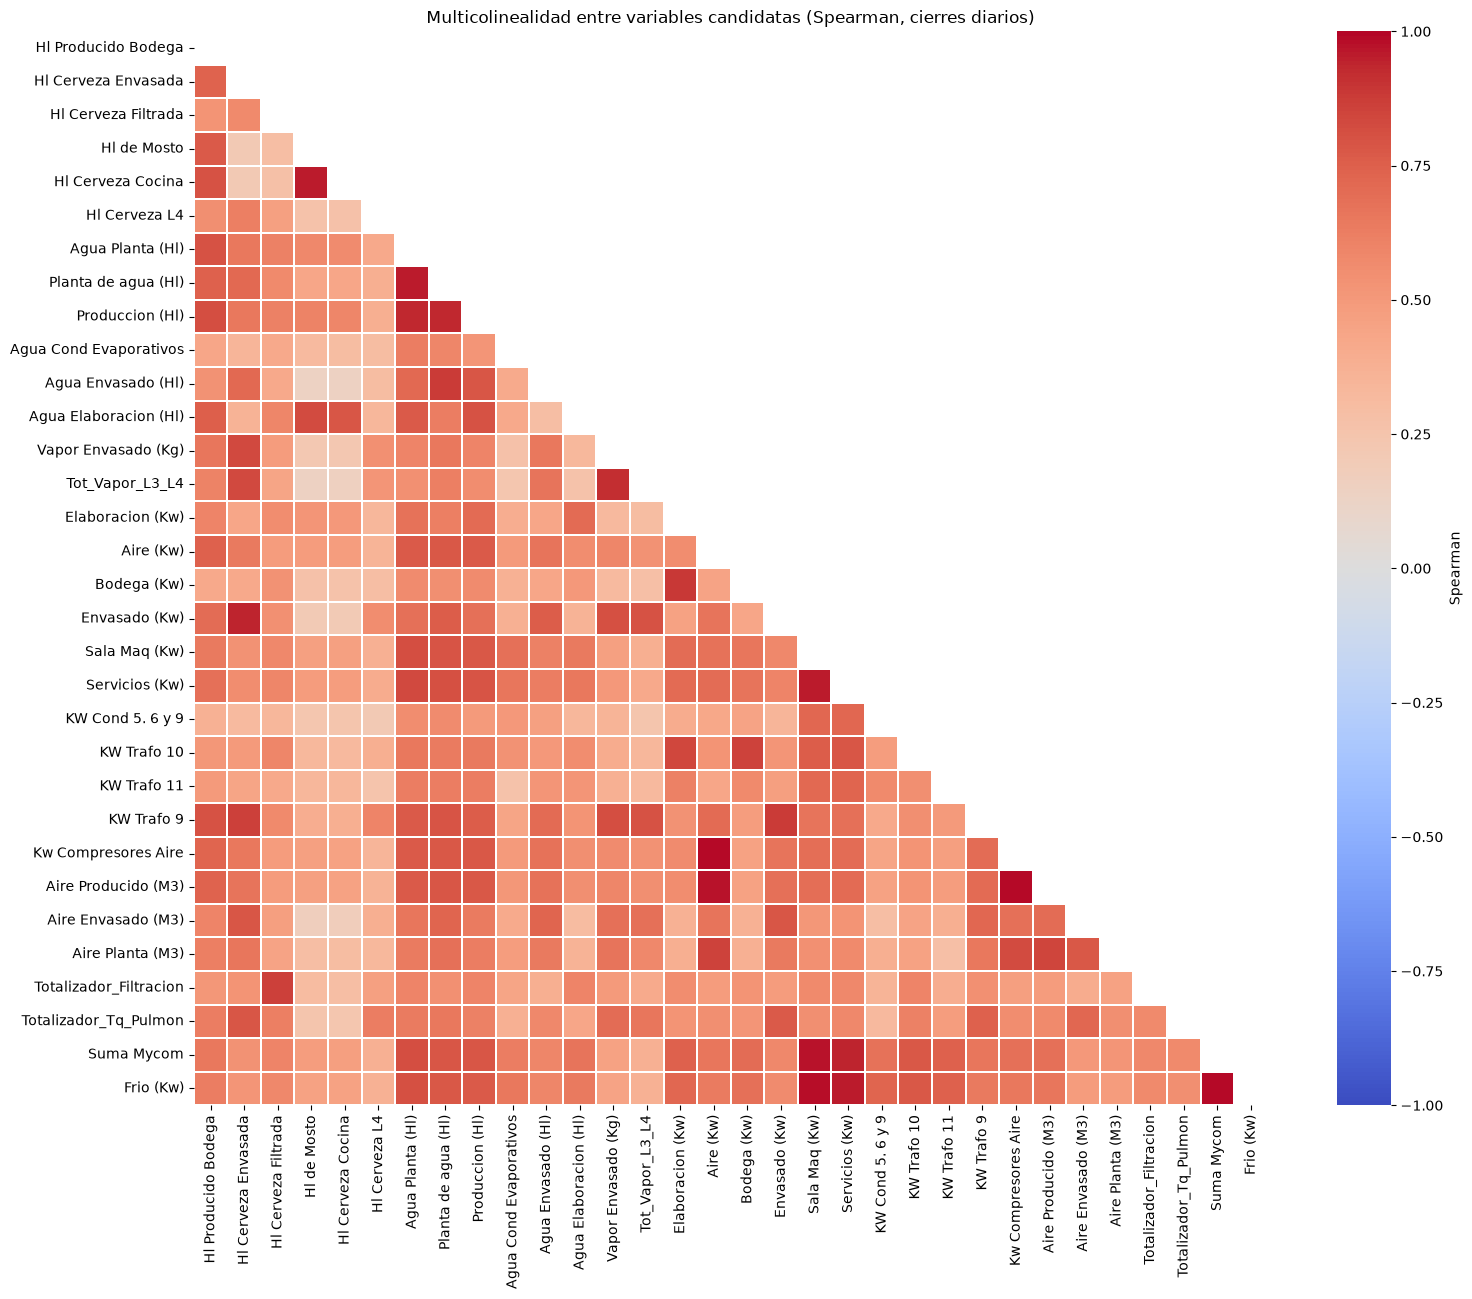

Pares con |Spearman| >= 0,9: 15
Suma Mycom           Frio (Kw)              0.990
Kw Compresores Aire  Aire Producido (M3)    0.989
Aire (Kw)            Kw Compresores Aire    0.986
Sala Maq (Kw)        Frio (Kw)              0.984
Aire (Kw)            Aire Producido (M3)    0.976
Sala Maq (Kw)        Suma Mycom             0.972
                     Servicios (Kw)         0.960
Agua Planta (Hl)     Planta de agua (Hl)    0.960
Hl de Mosto          Hl Cerveza Cocina      0.958
Servicios (Kw)       Frio (Kw)              0.957
                     Suma Mycom             0.945
Hl Cerveza Envasada  Envasado (Kw)          0.943
Agua Planta (Hl)     Produccion (Hl)        0.937
Planta de agua (Hl)  Produccion (Hl)        0.936
Vapor Envasado (Kg)  Tot_Vapor_L3_L4        0.920


In [37]:
corr = df_multi[columnas + ["Frio (Kw)"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(16, 13))
mascara = np.triu(np.ones_like(corr, dtype=bool))  # tapamos el triángulo de arriba (es espejo del de abajo)
sns.heatmap(corr, mask=mascara, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.3, cbar_kws={"label": "Spearman"}, ax=ax)
ax.set_title("Multicolinealidad entre variables candidatas (Spearman, cierres diarios)")
plt.tight_layout()
plt.show()

# Pares con |Spearman| >= 0,9: redundancia fuerte
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares = pares[pares.abs() >= 0.9].sort_values(key=abs, ascending=False)
print(f"Pares con |Spearman| >= 0,9: {len(pares)}")
print(pares.round(3).to_string())

Ranking (Spearman con el Frío de mañana):
Sala Maq (Kw)          0.829
Suma Mycom             0.826
Servicios (Kw)         0.818
Agua Planta (Hl)       0.715
Planta de agua (Hl)    0.705
KW Cond 5. 6 y 9       0.685
Produccion (Hl)        0.671
KW Trafo 10            0.627
KW Trafo 11            0.624
KW Trafo 9             0.606


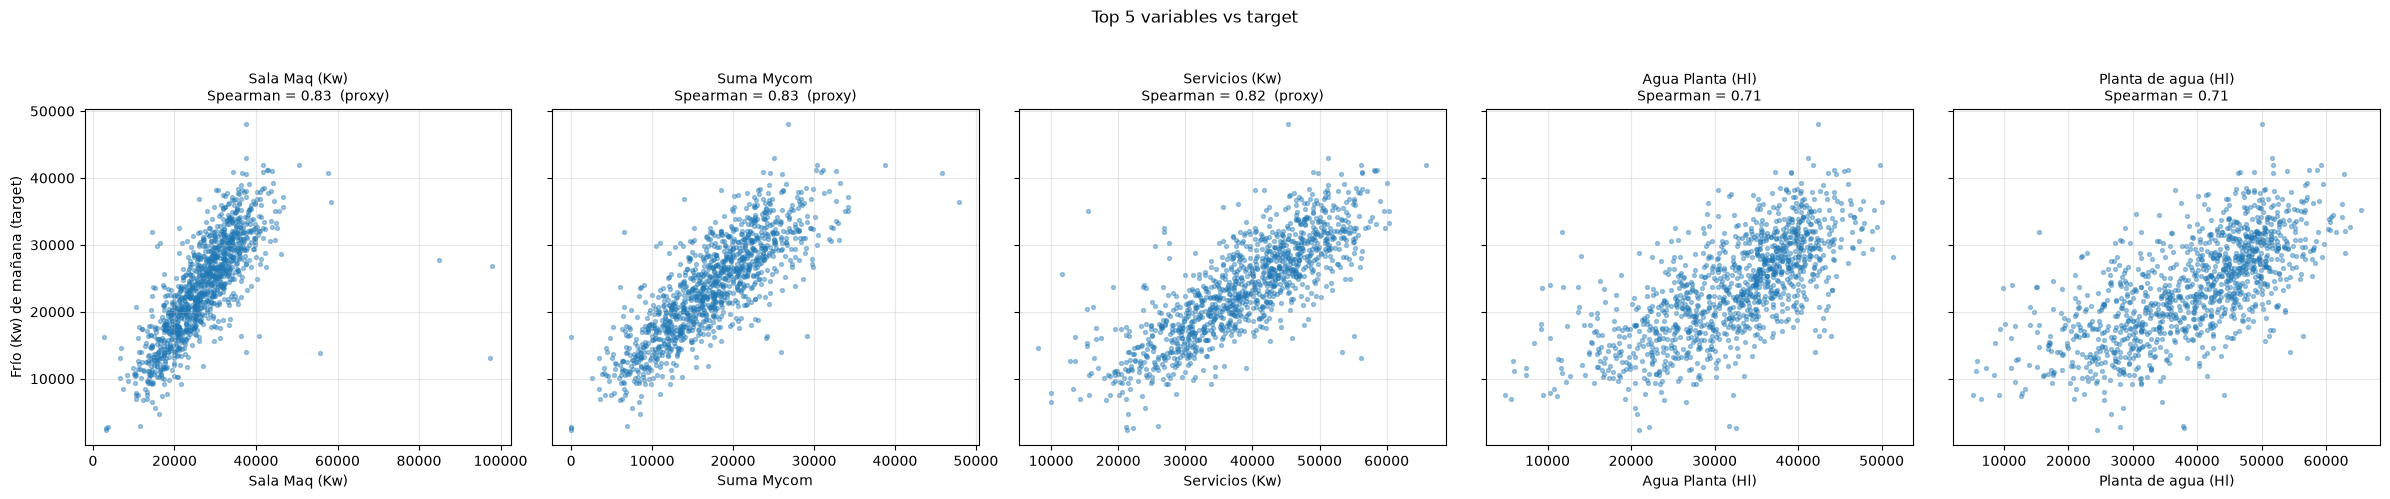

In [38]:
ranking = df_multi[columnas].corrwith(df_multi["Frio_manana"], method="spearman").sort_values(key=abs, ascending=False)
print("Ranking (Spearman con el Frío de mañana):")
print(ranking.round(3).head(10).to_string())

top5 = ranking.index[:5]
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8), sharey=True)
for ax, col in zip(axes, top5):
    ax.scatter(df_multi[col], df_multi["Frio_manana"], s=8, alpha=0.4)
    titulo = f"{col}\nSpearman = {ranking[col]:.2f}"
    if col in proxies:
        titulo += "  (proxy)"
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel(col)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Frío (Kw) de mañana (target)")
plt.suptitle("Top 5 variables vs target", y=1.03)
plt.tight_layout()
plt.show()

### Multicolinealidad y top 5 variables vs target

**Heatmap (Spearman, cierres diarios, extremos excluidos):** casi todas las variables candidatas se correlacionan positivamente entre sí (0,3 a 0,8), porque comparten un factor común: el nivel de actividad de la planta, que sigue la estacionalidad. Se identificaron 15 pares con |Spearman| ≥ 0,9, agrupados en 5 grupos redundantes, de los que se propone conservar una sola variable por grupo en la Fase 2.3:

| Grupo | Variables | Spearman |
|---|---|---|
| Proxies del target | Suma Mycom, Sala Maq (Kw), Servicios (Kw) y Frio (Kw) | 0,95 a 0,99 |
| Aire comprimido | Kw Compresores Aire, Aire Producido (M3), Aire (Kw) | 0,98 a 0,99 |
| Agua total | Agua Planta (Hl), Planta de agua (Hl), Produccion (Hl) | 0,94 a 0,96 |
| Cocina | Hl de Mosto, Hl Cerveza Cocina | 0,96 |
| Envasado | Hl Cerveza Envasada y Envasado (Kw) (0,94); Vapor Envasado (Kg) y Tot_Vapor_L3_L4 (0,92) | 0,92 a 0,94 |

**Variables con r > 0,98 con el Frío del mismo día:** `Suma Mycom` (0,990) y `Sala Maq (Kw)` (0,984). La primera es la suma del consumo de los 7 compresores de refrigeración; la segunda, el consumo de la sala de máquinas, del que el Frío representa ~89 %. Contienen al target. Usadas con valores del día D aportan lo mismo que el propio Frío de hoy: su Spearman con el Frío de mañana (0,83) coincide con la autocorrelación del Frío con rezago 1 (0,84). Usadas con valores del día D+1 constituirían fuga de información (leakage). **Decisión: no se usan como features.**

**Top 5 vs target (Frío de mañana):** `Sala Maq (Kw)` (0,83), `Suma Mycom` (0,83), `Servicios (Kw)` (0,82), `Agua Planta (Hl)` (0,72) y `Planta de agua (Hl)` (0,71). Las tres primeras son proxies; la mejor variable que aporta información distinta del propio Frío es `Agua Planta (Hl)`. En los scatter se observan:
- 4 cierres de `Sala Maq (Kw)` entre 80.000 y 97.000 kW que el filtro de extremos no excluyó (a tratar en la Fase 2.1).
- Días con `Suma Mycom` = 0 (los 7 compresores apagados), que coinciden con la parada de planta de fin de 2021 (Frío ≈ 2.500 kW), y un día con Frío ≈ 16.000 kW sin registro de compresores, a revisar.
- Mayor dispersión del target para valores altos de las variables (heterocedasticidad): los errores del modelo probablemente serán mayores en verano.